# PL5 — Exercise 3: One probe, two models
### Generative AI · MSc in Artificial Intelligence · Lab 5 

In Exercise 2 you trained a **decoder** (GPT-style) and an **encoder** (BERT-style) with the same code. Now you ask them **the same question**: *which character is missing here?*

```
encoder:   ... t h e   c ▁ t   s a t ...   ->  predicts ▁ using BOTH sides
decoder:   ... t h e   c                   ->  predicts the next char using the LEFT only
```

| Step | What you do | Time |
|---|---|---|
| 3.0 | load the two models from Exercise 2 (just run) | 1 min |
| 3.1 | write the decoder's prediction (one line) | 5 min |
| 3.2 | read five examples side by side | 3 min |
| Q | two short questions | 5 min |
| ★ | bonus: how much left context does the decoder need? | optional |

**Instructions.** Run the cells in order. Replace the `____` with **one line** of code, then run the `CHECK` cell right after it: ✅ means done. Stuck? Open the 💡 **Hint** — after trying for a minute.

**Names / student numbers:** _…_

### Setup
**Only if PyTorch or matplotlib is not installed** (on Google Colab both are already there): remove the `#` and run the cell, then restart the kernel.

In [1]:
# %pip install matplotlib torch --index-url https://download.pytorch.org/whl/cpu --extra-index-url https://pypi.org/simple

In [2]:
import math, os, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.12.0 | device: cpu


### The model and the data (nothing to do — just run)
The same Transformer as in Exercise 2: `causal=True` gives the decoder, `causal=False` the encoder. `[MASK]` is printed as `▁`.

In [3]:
class Block(nn.Module):
    def __init__(self, d, n_heads, causal=True):
        super().__init__()
        self.h, self.hd, self.causal = n_heads, d // n_heads, causal
        self.n1, self.n2 = nn.RMSNorm(d), nn.RMSNorm(d)
        self.qkv, self.proj = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))

    def mask(self, T, device):
        if not self.causal:
            return None                        # encoder: no mask at all -> everyone sees everyone
        i = torch.arange(T, device=device)[:, None]   # row    = query position
        j = torch.arange(T, device=device)[None, :]   # column = key position
        return j <= i                          # decoder: query i may only read keys j <= i

    def forward(self, x):
        B, T, C = x.shape
        h = self.n1(x)
        q, k, v = [t.view(B, T, self.h, self.hd).transpose(1, 2) for t in self.qkv(h).split(C, -1)]
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=self.mask(T, x.device))
        x = x + self.proj(a.transpose(1, 2).reshape(B, T, C))
        return x + self.ffn(self.n2(x))


class Transformer(nn.Module):
    # One architecture, two behaviours: causal LM (causal=True) or masked LM (causal=False).
    def __init__(self, vocab, d=128, n_layers=2, n_heads=4, context=128, causal=True):
        super().__init__()
        self.context = context
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(context, d)
        self.blocks = nn.ModuleList([Block(d, n_heads, causal) for _ in range(n_layers)])
        self.norm, self.head = nn.RMSNorm(d), nn.Linear(d, vocab, bias=False)
        self.head.weight = self.tok.weight
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx):                    # idx: (B, T) token ids  ->  logits: (B, T, vocab)
        x = self.tok(idx) + self.pos(torch.arange(idx.size(1), device=idx.device))
        for b in self.blocks:
            x = b(x)
        return self.head(self.norm(x))

print("ok")

ok


In [4]:
with open("data/tiny_shakespeare.txt", encoding="utf-8") as f:
    text = f.read()
chars = sorted(set(text))
MASK = len(chars)                      # one extra id for [MASK]
V = len(chars) + 1
stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(chars[i] if i < len(chars) else "▁" for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]
CTX, BATCH = 128, 32
STEPS = 800 if device == "cuda" else 500
print(f"V = {V} (including [MASK] = {MASK}), {len(train_data):,} train characters, {STEPS} steps for the GPT")

def get_batch(split, batch=BATCH, context=CTX):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - context - 1, (batch,))
    x = torch.stack([src[i:i + context] for i in ix])
    y = torch.stack([src[i + 1:i + context + 1] for i in ix])   # y = x shifted one to the left
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("x[0]:", repr(decode(xb[0, :50].tolist())))
print("y[0]:", repr(decode(yb[0, :50].tolist())), " <- the same text, one character later")

V = 66 (including [MASK] = 65), 1,003,854 train characters, 500 steps for the GPT
x[0]: 'aith of heart\nTo his most royal person, hither com'
y[0]: 'ith of heart\nTo his most royal person, hither come'  <- the same text, one character later


### 3.0 — Load the two models (just run)
The cell looks for `gpt.pt` and `bert.pt`, saved at the end of Exercise 2 — **copy them into this folder** first.
If they are not there, it trains both models again with the code of Exercise 2 (about 5–7 minutes on a laptop CPU, under a minute on a GPU).

In [5]:
def mlm_batch(x, p=0.15):
    x = x.clone()                                   # never modify the caller's tensor
    targets = torch.full_like(x, -100)              # -100 everywhere = "no loss here"
    chosen = torch.rand(x.shape, device=x.device) < p
    r = torch.rand(x.shape, device=x.device)
    to_mask = chosen & (r < 0.8)
    to_random = chosen & (r >= 0.8) & (r < 0.9)

    targets[chosen] = x[chosen]                     # the ORIGINAL tokens at the chosen positions
    x[to_mask] = MASK
    x[to_random] = torch.randint(0, MASK, (int(to_random.sum()),), device=x.device)
    return x, targets


def causal_loss(model, xb, yb):
    logits = model(xb)                       # (B, T, V)
    return F.cross_entropy(logits.reshape(-1, V), yb.reshape(-1))


def mlm_loss(model, xb):
    xc, tg = mlm_batch(xb)                   # corrupted input + targets (-100 almost everywhere)
    logits = model(xc)                       # (B, T, V)
    return F.cross_entropy(logits.reshape(-1, V), tg.reshape(-1), ignore_index=-100)


def train(model, loss_fn, steps=STEPS, lr=2e-3, label=""):
    model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 50) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    t0, hist = time.time(), []
    for step in range(steps):
        xb, yb = get_batch("train")
        loss = loss_fn(model, xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if step % 50 == 0:
            hist.append((step, loss.item()))
        if step % 200 == 0:
            print(f"  {label} step {step:5d}  loss {loss.item():.3f}")
    print(f"{label:22s} final loss {loss.item():.3f}  ({time.time() - t0:.0f}s)\n")
    return model, hist


gpt = Transformer(V, causal=True, context=CTX).to(device)
bert = Transformer(V, causal=False, context=CTX).to(device)
if os.path.exists("gpt.pt") and os.path.exists("bert.pt"):
    gpt.load_state_dict(torch.load("gpt.pt", map_location=device))
    bert.load_state_dict(torch.load("bert.pt", map_location=device))
    print("✅ loaded gpt.pt and bert.pt from Exercise 2")
else:
    print("gpt.pt / bert.pt not found -> training both models (this takes a few minutes)\n")
    torch.manual_seed(1337)
    gpt, _ = train(gpt, lambda m, x, y: causal_loss(m, x, y), steps=STEPS, label="causal (GPT-style)")
    torch.manual_seed(1337)
    bert, _ = train(bert, lambda m, x, y: mlm_loss(m, x), steps=3 * STEPS, label="masked (BERT-style)")
    torch.save(gpt.state_dict(), "gpt.pt"); torch.save(bert.state_dict(), "bert.pt")
    print("saved gpt.pt and bert.pt")
gpt.eval(); bert.eval();

✅ loaded gpt.pt and bert.pt from Exercise 2


---
## 3.1 — The same probe for both models
Take held-out text and hide **one** character in the middle of each window (position `pos`):

```
encoder:   ... t h e   c ▁ t   s a t ...   ->  predict ▁ using BOTH sides
decoder:   ... t h e   c                   ->  predict the next char using the LEFT only
```

The encoder line is given. Write the decoder line.


<details><summary>💡 <b>Hint</b> (try first!)</summary>

The decoder makes its prediction for position `pos` at the position **before** it: take `gpt(xb)[:, pos - 1]` and then `.argmax(-1)`. You can give it the original `xb` (with the true character at `pos`): thanks to the causal mask, position `pos - 1` cannot see it anyway.

</details>

In [6]:
@torch.no_grad()
def probe(n=256, pos=CTX // 2):
    gpt.eval(); bert.eval()
    xb, _ = get_batch("val", batch=n)
    truth = xb[:, pos].clone()

    # encoder: hide position pos with [MASK] and read the prediction AT pos (given)
    xm = xb.clone()
    xm[:, pos] = MASK
    enc_pred = bert(xm)[:, pos].argmax(-1)

    # decoder: the logits at position pos-1 predict position pos
    dec_pred = gpt(xb)[:, pos - 1].argmax(-1)           # TODO

    acc = {"encoder (both sides)": (enc_pred == truth).float().mean().item(),
           "decoder (left only)":  (dec_pred == truth).float().mean().item()}
    return acc, xb, truth, enc_pred, dec_pred

torch.manual_seed(0)
acc, xb, truth, enc_pred, dec_pred = probe()
for k, v in acc.items():
    print(f"{k:24s} {v:.1%}")


encoder (both sides)     48.0%
decoder (left only)      31.6%


In [7]:
# CHECK 3.1
gap = acc["encoder (both sides)"] - acc["decoder (left only)"]
assert acc["encoder (both sides)"] > 0.25 and acc["decoder (left only)"] > 0.25, f"both models should beat 25% — did the training run to the end? {acc}"
assert gap > -0.05, f"the encoder should not be clearly worse at filling a gap (gap {gap:+.3f})"
print(f"✅ 3.1 OK — encoder beats decoder by {gap:+.1%}")

✅ 3.1 OK — encoder beats decoder by +16.4%


## 3.2 — Five examples side by side (just run)
`_?_` is the hidden character. Look for cases where the **right** context gives the answer away — the encoder can use it, the decoder cannot.

In [8]:
P = CTX // 2
print("\nfive examples:")
for i in range(5):
    left, right = decode(xb[i, P - 20:P].tolist()), decode(xb[i, P + 1:P + 21].tolist())
    print(f"{left!r:>24} _?_ {right!r:<24} truth {decode([truth[i].item()])!r:5} | enc {decode([enc_pred[i].item()])!r:5} | dec {decode([dec_pred[i].item()])!r}")


five examples:
'or first.\n\nTRANIO:\nA' _?_ 'd I am one that love'   truth 'n'   | enc 'n'   | dec 'n'
 'd as may beseem\nThe ' _?_ 'pouse of any noble g'   truth 's'   | enc 's'   | dec 't'
  'a suitor to your dau' _?_ 'hter,\nUnto Bianca, f'  truth 'g'   | enc 'g'   | dec 'r'
 'aking, moving,\nAnd y' _?_ 't so fast asleep.\n\nA' truth 'e'   | enc 'a'   | dec 'o'
'\nSEBASTIAN:\nA dollar' _?_ '\n\nGONZALO:\nDolour co' truth '.'   | enc '.'   | dec ' '


---
## Questions

**Q1.** The encoder wins the probe because… *(choose one and justify in one sentence)*
- (A) it was trained for more steps;
- (B) it sees the characters on **both sides** of the gap, the decoder only those on the left;
- (C) the encoder has more parameters.

**Q2.** Complete the sentence: *"To generate text from left to right, at position t the model cannot see ______, so the encoder's advantage ______. That is why BERT is not a chatbot (lecture, Q1)."*

**Your answers:**

Q1: (B). The encoder has bidirectional context (both left and right of the missing character), giving it much more information to infer the missing token, while the decoder is restricted by the causal mask to only the left context.

Q2: To generate text from left to right, at position t the model cannot see the future / right context, so the encoder's advantage disappears. That is why BERT is not a chatbot (lecture, Q1).


---
## ★ Bonus (optional, no training needed): how much left context does the decoder need?
The encoder always has context on both sides. The decoder only has what is on the left of the gap.
Run the probe with the gap at different positions and look at what happens near the **start** of the window.

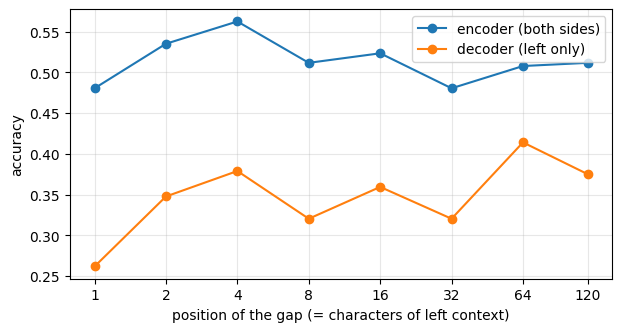

In [9]:
torch.manual_seed(0)
positions = [1, 2, 4, 8, 16, 32, 64, 120]
enc_acc, dec_acc = [], []
for pos in positions:
    a, *_ = probe(pos=pos)
    enc_acc.append(a["encoder (both sides)"]); dec_acc.append(a["decoder (left only)"])

plt.figure(figsize=(7, 3.5))
plt.plot(positions, enc_acc, "o-", label="encoder (both sides)")
plt.plot(positions, dec_acc, "o-", label="decoder (left only)")
plt.xscale("log", base=2); plt.xticks(positions, positions)
plt.xlabel("position of the gap (= characters of left context)"); plt.ylabel("accuracy")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Bonus question.** Where is the gap between the two models largest, and why? What does this tell you about which architecture you would pick to **fill in** a missing word versus to **continue** a text?

**Your answer:** The gap is largest at the beginning of the window (small positions like pos = 1 or 2), because the decoder has virtually zero left context to guess from, whereas the encoder still enjoys almost the entire sequence from the right side. This shows that encoder architectures (BERT-style) are ideal for filling in missing tokens and understanding complete texts, whereas decoder architectures (GPT-style) are necessary for continuing/generating text autoregressively from left to right.
